# Hierarchical Bayesian RL Model Comparison
This notebook fits and compares four hierarchical Rescorla-Wagner reinforcement learning models across all participants:
1. **Model 1 (`1. single alpha`):** Single learning rate ($\alpha$) and inverse temperature ($\beta$).
2. **Model 2 (`2. valence`):** Two learning rates split by prediction error valence ($\alpha_{pos}, \alpha_{neg}$) and $\beta$.
3. **Model 3 (`3. task`):** Two learning rates ($\alpha_{win}, \alpha_{lose}$) and inverse temperatures ($\beta_{win}, \beta_{lose}$) split by task domain.
4. **Model 4 (`4. task x valence`):** Four learning rates split by both task domain and prediction error valence ($\alpha_{win,pos}, \alpha_{win,neg}, \alpha_{lose,pos}, \alpha_{lose,neg}$) and $\beta$.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import warnings

from learning_functions import (
    prepare_vectorized_bandit_data,
    step_m1_vec, step_m2_vec, step_m3_vec, step_m4_vec,
    add_bernoulli_ll
)

warnings.filterwarnings('ignore')


In [2]:
# Load and vectorize data into (max_t, n_sub) subject-batched tensors
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

print(f"Total subjects: {n_sub}")
print(f"Total trials across all subjects: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects: 67
Total trials across all subjects: 6520 (Vectorized scan length: 100 steps)


In [3]:
def make_hierarchical_alpha(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=1.5)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.invlogit(mu + raw * sigma))

def make_hierarchical_beta(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=2.0)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.exp(mu + raw * sigma))

def build_model_1(vdata):
    """Model 1: Hierarchical Single Alpha, Single Beta (Vectorized across subjects)"""
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as m1:
        alpha = make_hierarchical_alpha('alpha', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m1_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        pm.Deterministic('Q_values_pre_update', results[3][t_idx, s_idx, :])
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return m1

def build_model_2(vdata):
    """Model 2: Hierarchical Valence (Alpha split by PE), Single Beta (Vectorized across subjects)"""
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as m2:
        alpha_pos = make_hierarchical_alpha('alpha_pos', n_sub)
        alpha_neg = make_hierarchical_alpha('alpha_neg', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m2_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha_pos, alpha_neg],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        pm.Deterministic('Q_values_pre_update', results[3][t_idx, s_idx, :])
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return m2

def build_model_3(vdata):
    """Model 3: Hierarchical Task (Alpha & Beta split by domain, Vectorized across subjects)"""
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as m3:
        alpha_win = make_hierarchical_alpha('alpha_win', n_sub)
        alpha_lose = make_hierarchical_alpha('alpha_lose', n_sub)
        beta_win = make_hierarchical_beta('beta_win', n_sub)
        beta_lose = make_hierarchical_beta('beta_lose', n_sub)
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m3_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
                pt.as_tensor_variable(vdata['win_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha_win, alpha_lose],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        pm.Deterministic('Q_values_pre_update', results[3][t_idx, s_idx, :])
        is_win_seq = vdata['win_mat'][t_idx, s_idx]
        beta_seq = pt.switch(is_win_seq, beta_win[s_idx], beta_lose[s_idx])
        p_right_raw = pm.math.sigmoid(beta_seq * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return m3

def build_model_4(vdata):
    """Model 4: Hierarchical Task x Valence (4 Alphas: Win/Lose x Pos/Neg PE, Vectorized across subjects)"""
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as m4:
        alpha_win_pos = make_hierarchical_alpha('alpha_win_pos', n_sub)
        alpha_win_neg = make_hierarchical_alpha('alpha_win_neg', n_sub)
        alpha_lose_pos = make_hierarchical_alpha('alpha_lose_pos', n_sub)
        alpha_lose_neg = make_hierarchical_alpha('alpha_lose_neg', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m4_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
                pt.as_tensor_variable(vdata['win_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha_win_pos, alpha_win_neg, alpha_lose_pos, alpha_lose_neg],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        pm.Deterministic('Q_values_pre_update', results[3][t_idx, s_idx, :])
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return m4


In [4]:
# Fit all 4 models using nutpie (PyMC 6)
y_obs = df['Choice'].values

print("--- Building and Sampling Model 1 (Single Alpha) ---")
m1 = build_model_1(vdata)
with m1:
    idata_1 = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
    add_bernoulli_ll(idata_1, y_obs)

print("--- Building and Sampling Model 2 (Valence: 2 Alphas) ---")
m2 = build_model_2(vdata)
with m2:
    idata_2 = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
    add_bernoulli_ll(idata_2, y_obs)

print("--- Building and Sampling Model 3 (Task: 2 Alphas, 2 Betas) ---")
m3 = build_model_3(vdata)
with m3:
    idata_3 = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
    add_bernoulli_ll(idata_3, y_obs)

print("--- Building and Sampling Model 4 (Task x Valence: 4 Alphas) ---")
m4 = build_model_4(vdata)
with m4:
    idata_4 = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
    add_bernoulli_ll(idata_4, y_obs)


--- Building and Sampling Model 1 (Single Alpha) ---


NUTS[nutpie]: [alpha_mu, alpha_sigma, alpha_raw, beta_mu, beta_sigma, beta_raw]


Output()

--- Building and Sampling Model 2 (Valence: 2 Alphas) ---


NUTS[nutpie]: [alpha_pos_mu, alpha_pos_sigma, alpha_pos_raw, alpha_neg_mu, alpha_neg_sigma, alpha_neg_raw, beta_mu, beta_sigma, beta_raw]


Output()

... (2 outputs left out)

Output()

--- Building and Sampling Model 4 (Task x Valence: 4 Alphas) ---


NUTS[nutpie]: [alpha_win_pos_mu, alpha_win_pos_sigma, alpha_win_pos_raw, alpha_win_neg_mu, alpha_win_neg_sigma, alpha_win_neg_raw, alpha_lose_pos_mu, alpha_lose_pos_sigma, alpha_lose_pos_raw, alpha_lose_neg_mu, alpha_lose_neg_sigma, alpha_lose_neg_raw, beta_mu, beta_sigma, beta_raw]


Output()

In [5]:
# Model Comparison
comp_dict = {
    "1. single alpha": idata_1,
    "2. valence": idata_2,
    "3. task": idata_3,
    "4. task x valence": idata_4
}
comp = az.compare(comp_dict)
print("\nOverall Model Comparison (LOO):")
display(comp)



Overall Model Comparison (LOO):


,rank,elpd,p,elpd_diff,weight,se,dse,warning
4. task x valence,0,-2890.0,172.4,0.0,0.85,44.0,0.0,True
3. task,1,-2910.0,164.6,-20.0,0.01,44.0,6.9,True
2. valence,2,-2910.0,151.2,-20.0,0.02,44.0,7.8,True
1. single alpha,3,-2930.0,108.4,-50.0,0.12,44.0,11.0,True


Plotting results for winning model: 4. task x valence


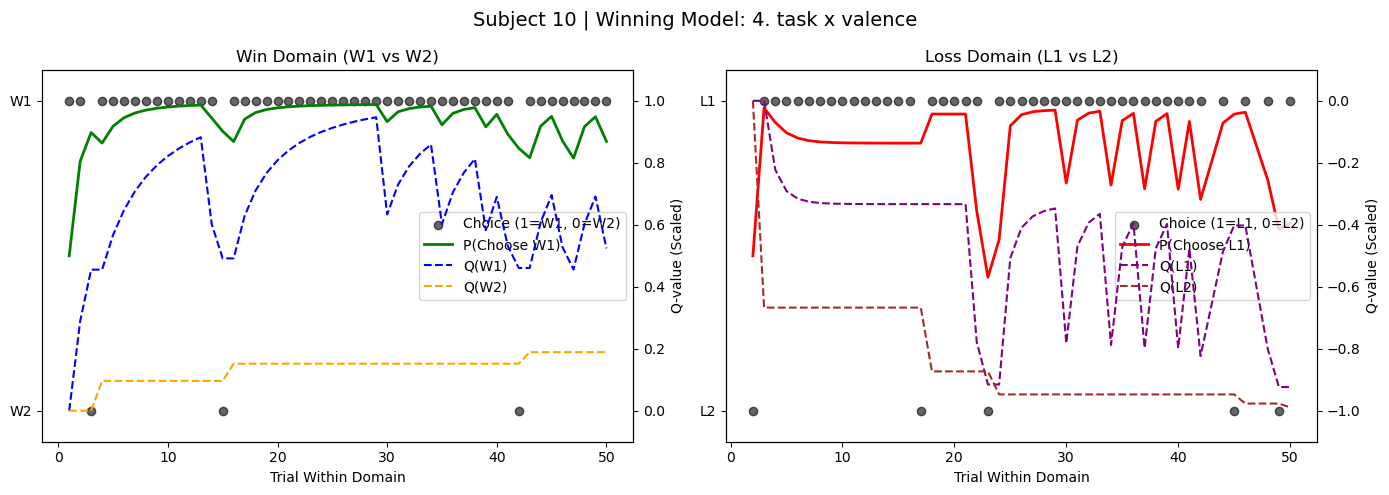

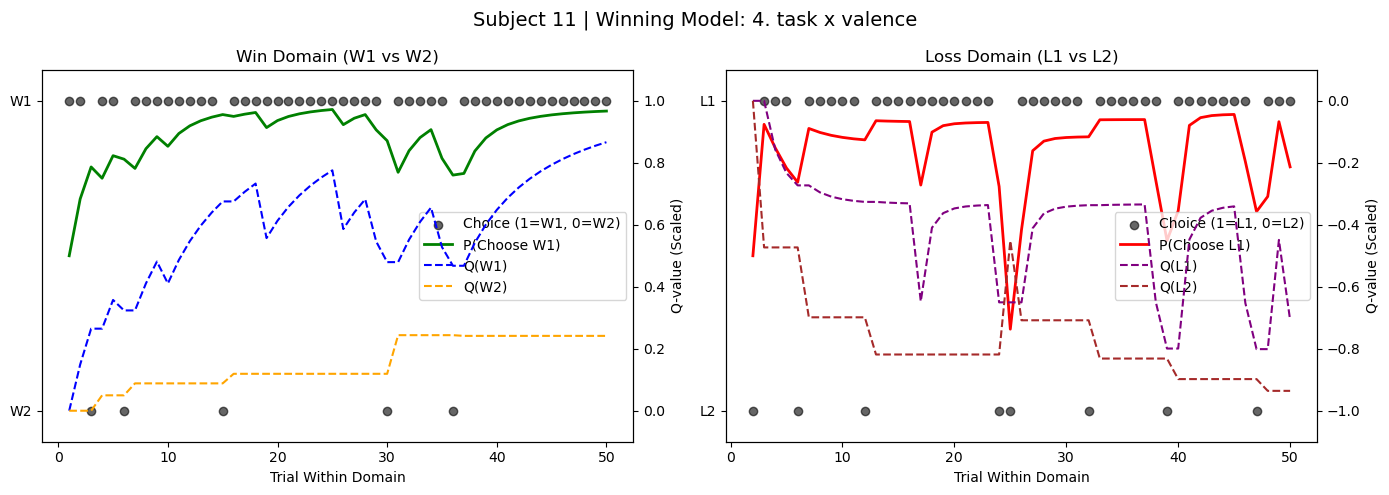

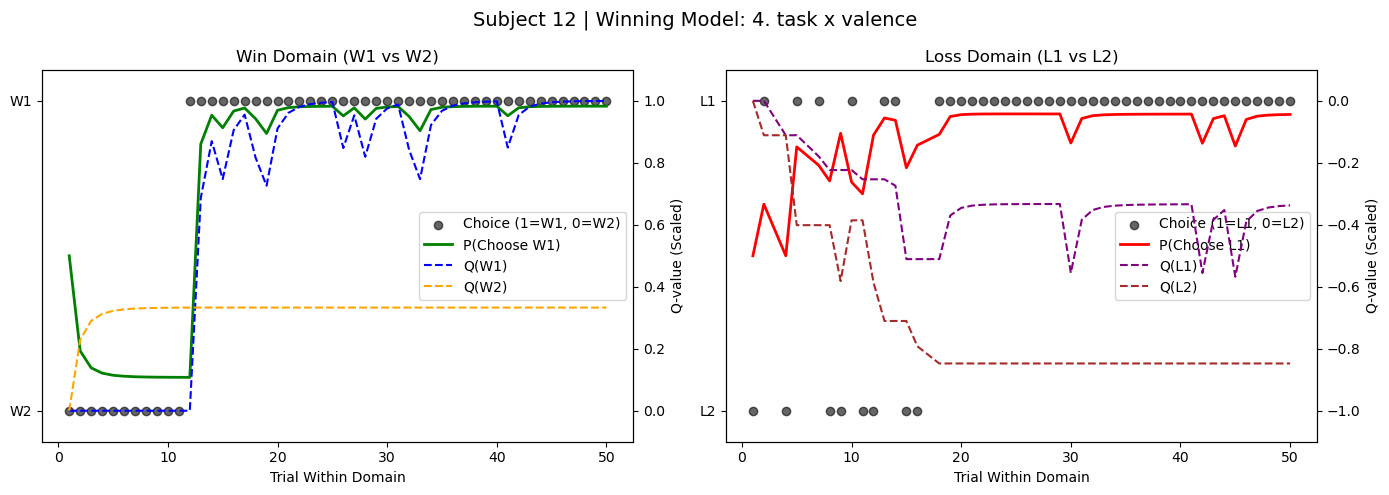

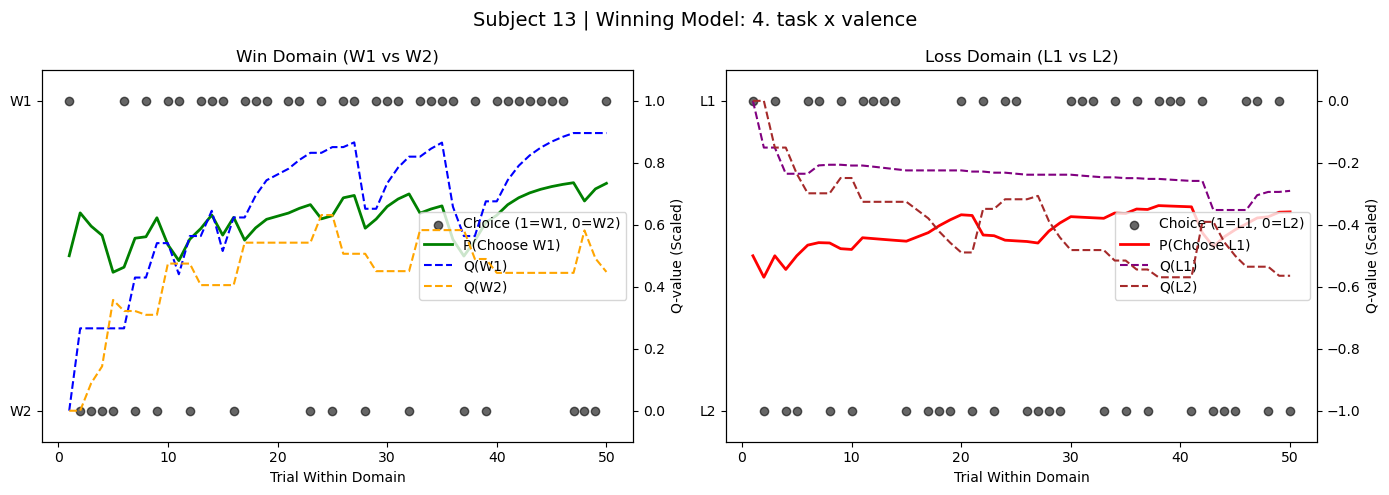

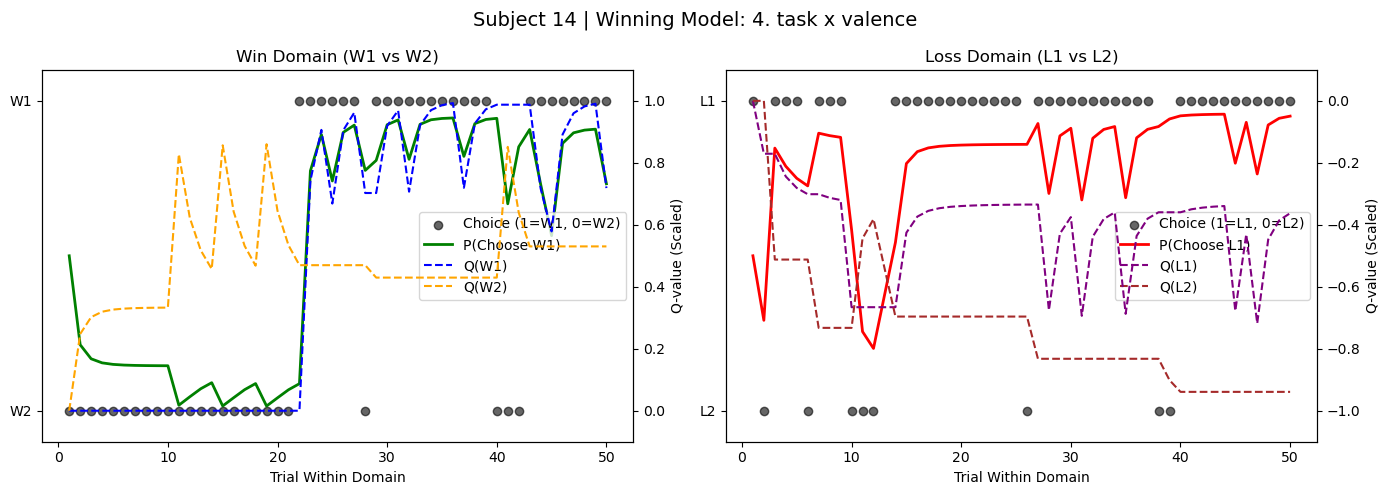

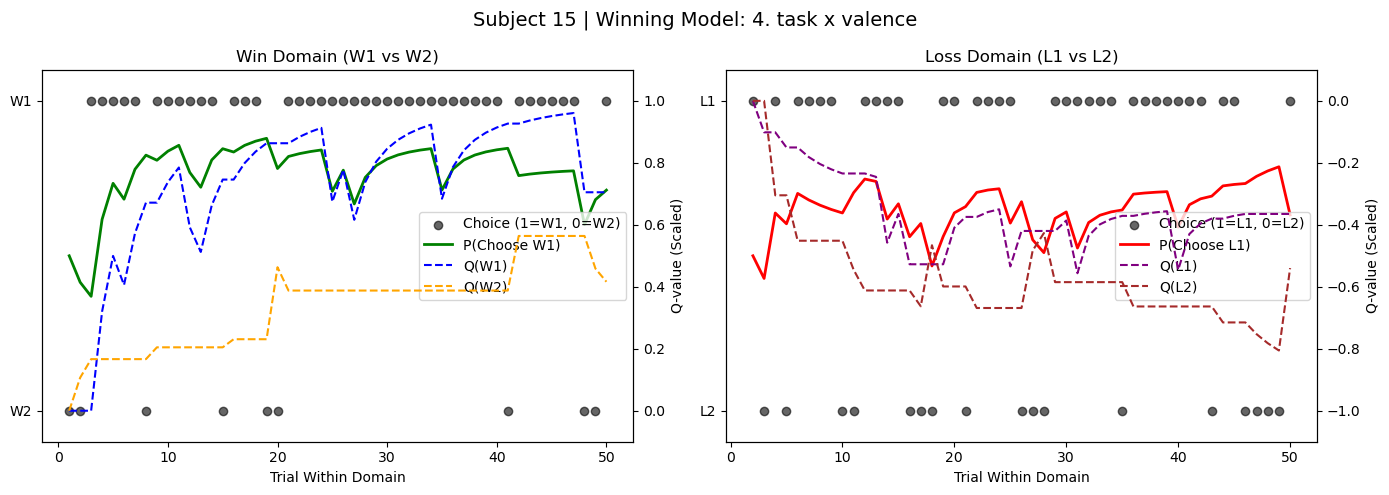

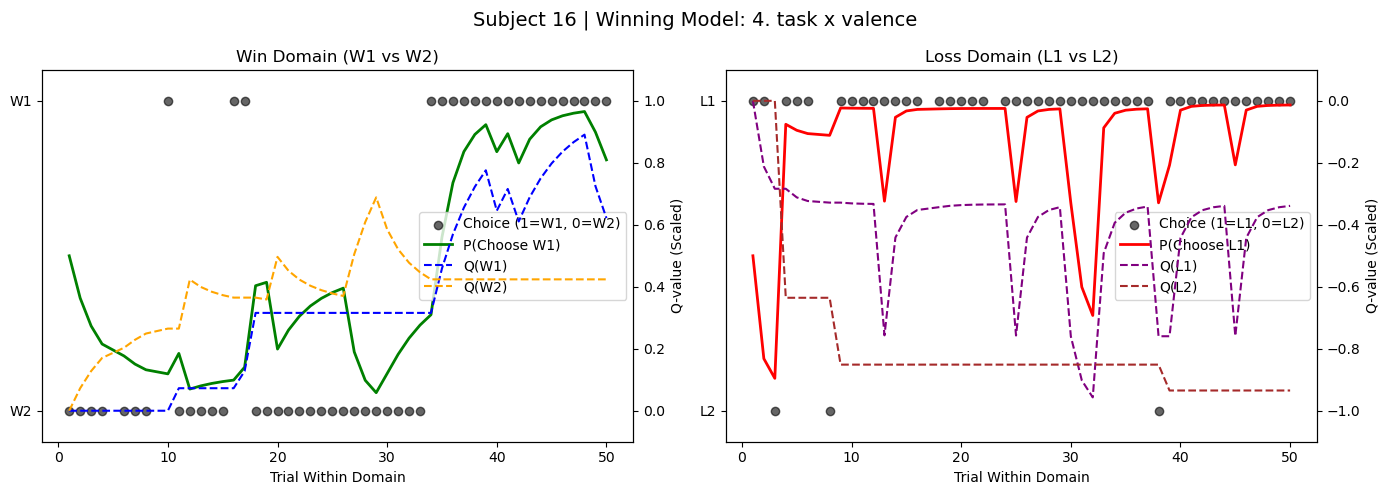

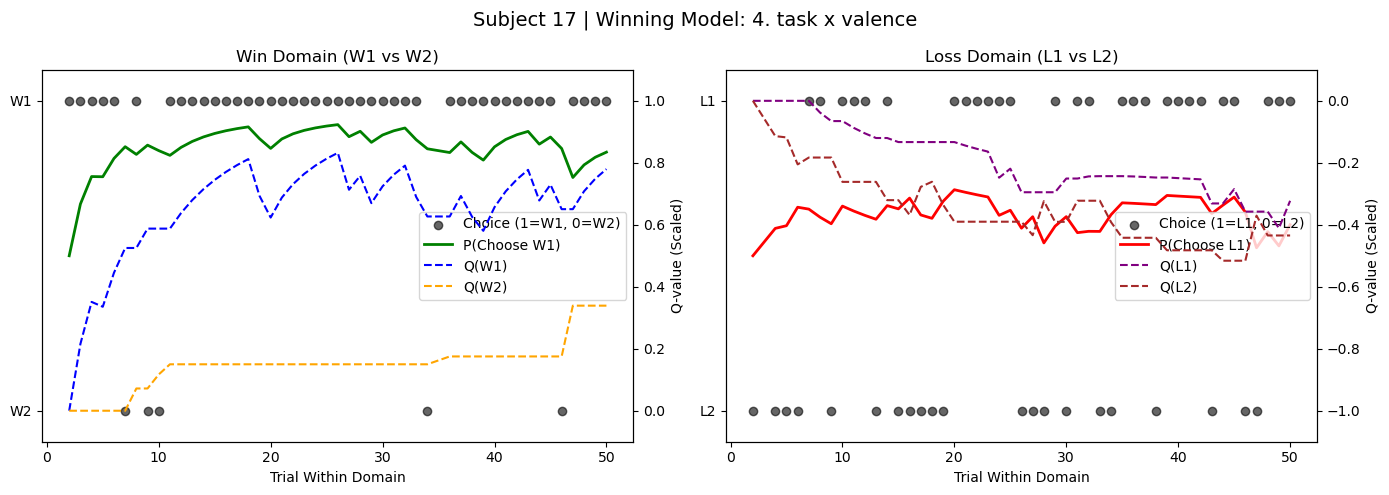

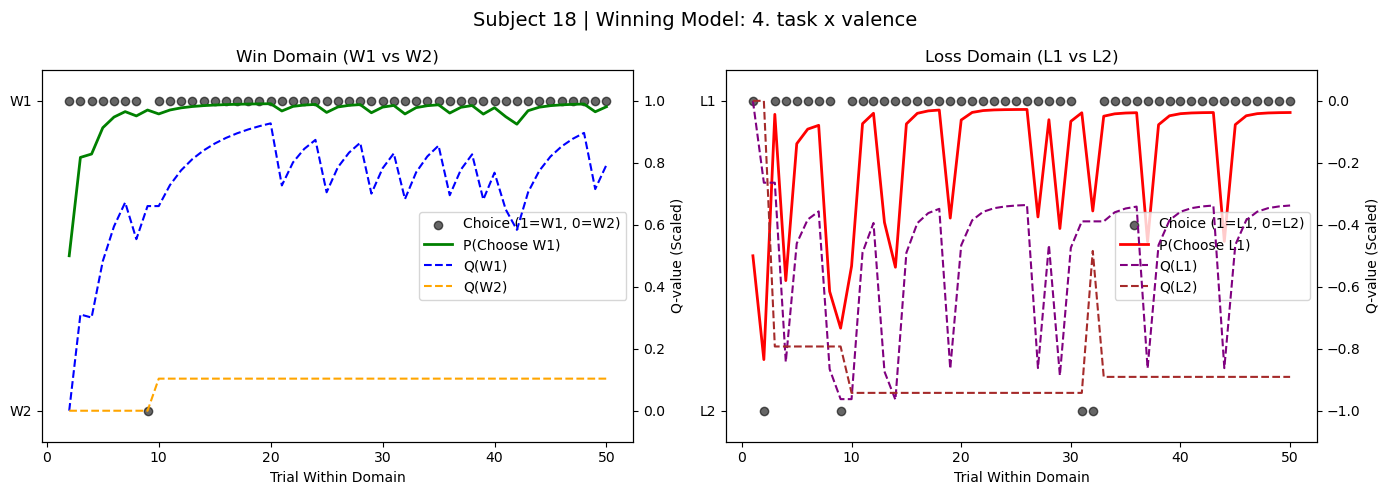

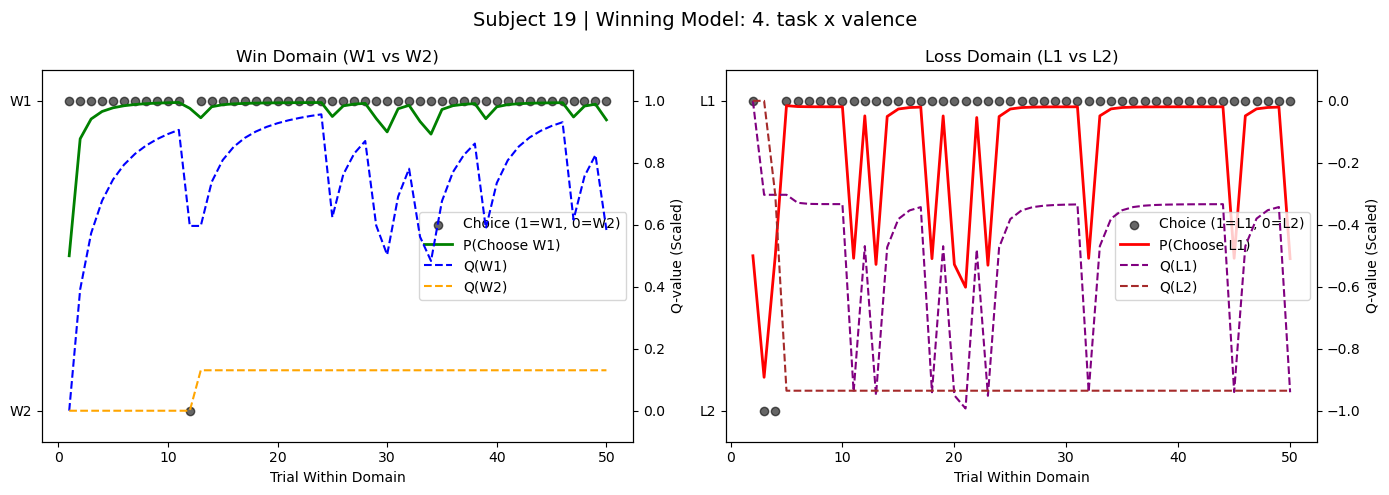

In [6]:
def get_p_opt1(row, opt1_id):
    if row['RightID'] == opt1_id:
        return row['P_Right']
    elif row['LeftID'] == opt1_id:
        return 1.0 - row['P_Right']
    return np.nan

def plot_winning_model(df, idata, model_name, n_sub):
    """
    Plots the winning model's fit for each participant.
    """
    Q_mean = idata.posterior['Q_values_pre_update'].mean(dim=['chain', 'draw']).values
    p_right_mean = idata.posterior['p_right'].mean(dim=['chain', 'draw']).values
    
    df = df.copy()
    df['P_Right'] = p_right_mean
    df['P_W1'] = df.apply(lambda r: get_p_opt1(r, 'W1') if r['TrialType'] == 'W' else np.nan, axis=1)
    df['P_L1'] = df.apply(lambda r: get_p_opt1(r, 'L1') if r['TrialType'] == 'L' else np.nan, axis=1)
    
    unique_subs = df['Sub'].unique()
    
    for sub in unique_subs[:10]: # Plotting only top 3 as example
        df_sub = df[df['Sub'] == sub].copy()
        sub_idx = df_sub['SubIdx'].iloc[0]
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
        fig.suptitle(f"Subject {sub} | Winning Model: {model_name}", fontsize=14)
        
        # Win Domain
        ax_w = axes[0]
        df_w = df_sub[df_sub['TrialType'] == 'W']
        if not df_w.empty:
            x_w = df_w['IdxWithinType'].values
            choices_w = (df_w['ChosenID'] == 'W1').astype(int).values
            ax_w.scatter(x_w, choices_w, color='black', alpha=0.6, label='Choice (1=W1, 0=W2)')
            ax_w.plot(x_w, df_w['P_W1'].values, color='green', label='P(Choose W1)', lw=2)
            
            ax_w.set_title("Win Domain (W1 vs W2)")
            ax_w.set_xlabel("Trial Within Domain")
            ax_w.set_yticks([0, 1])
            ax_w.set_yticklabels(['W2', 'W1'])
            ax_w.set_ylim(-0.1, 1.1)
            
            ax_qw = ax_w.twinx()
            ax_qw.plot(x_w, Q_mean[df_w.index, 0], color='blue', linestyle='--', label='Q(W1)')
            ax_qw.plot(x_w, Q_mean[df_w.index, 1], color='orange', linestyle='--', label='Q(W2)')
            ax_qw.set_ylabel("Q-value (Scaled)")
            ax_qw.set_ylim(-0.1, 1.1)
            
            lines, labels = ax_w.get_legend_handles_labels()
            lines2, labels2 = ax_qw.get_legend_handles_labels()
            ax_w.legend(lines + lines2, labels + labels2, loc='center right')
            
        # Lose Domain
        ax_l = axes[1]
        df_l = df_sub[df_sub['TrialType'] == 'L']
        if not df_l.empty:
            x_l = df_l['IdxWithinType'].values
            choices_l = (df_l['ChosenID'] == 'L1').astype(int).values
            ax_l.scatter(x_l, choices_l, color='black', alpha=0.6, label='Choice (1=L1, 0=L2)')
            ax_l.plot(x_l, df_l['P_L1'].values, color='red', label='P(Choose L1)', lw=2)
            
            ax_l.set_title("Loss Domain (L1 vs L2)")
            ax_l.set_xlabel("Trial Within Domain")
            ax_l.set_yticks([0, 1])
            ax_l.set_yticklabels(['L2', 'L1'])
            ax_l.set_ylim(-0.1, 1.1)
            
            ax_ql = ax_l.twinx()
            ax_ql.plot(x_l, Q_mean[df_l.index, 2], color='purple', linestyle='--', label='Q(L1)')
            ax_ql.plot(x_l, Q_mean[df_l.index, 3], color='brown', linestyle='--', label='Q(L2)')
            ax_ql.set_ylabel("Q-value (Scaled)")
            ax_ql.set_ylim(-1.1, 0.1)
            
            lines, labels = ax_l.get_legend_handles_labels()
            lines2, labels2 = ax_ql.get_legend_handles_labels()
            ax_l.legend(lines + lines2, labels + labels2, loc='center right')
            
        plt.tight_layout()
        plt.show()

# Plot winner
winning_model_name = comp.index[0]
winning_idata = comp_dict[winning_model_name]
print(f"Plotting results for winning model: {winning_model_name}")
plot_winning_model(df, winning_idata, winning_model_name, n_sub)
